In [ ]:
import torch
import numpy as np
import pandas as pd
import re
import os
import matplotlib.pyplot as plt
import torchvision
import tqdm
import glob
from PIL import Image
import seaborn as sns
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

import sys
sys.path.append('../../vision')

import datasets
import training_loop
import losses
import models
import optimizers

if torch.cuda.is_available():
    device = torch.device('cuda:0')
else:
    device = torch.device('cpu')
print(device)
s3d_or_vit = 'vit'
labels = pd.read_csv("../../labels/semi_cleaned_labels_3_features_2024-10-21.csv")
labels = labels.drop(columns=['MRN','SURGERY_DATE'])

new_labels = labels.replace('nan', np.nan)
new_labels = new_labels.replace('nc', np.nan)

# drop nans:
new_labels.dropna(inplace=True) # needs to happen before sorting into pre and post

new_labels_pre = new_labels[['ACC_NUM','LVEF_pre','RVSF_pre','TR_pre']]
new_labels_pre.columns = ['ACC_NUM','LVEF','RVSF','TR']
new_labels_pre['prepost'] = 0

new_labels_post = new_labels[['ACC_NUM','LVEF_post','RVSF_post','TR_post']]
new_labels_post.columns = ['ACC_NUM','LVEF','RVSF','TR']
new_labels_post['prepost'] = 1

new_labels = pd.concat([new_labels_pre, new_labels_post])
new_labels.reset_index(drop=True, inplace=True)

new_labels['LVEF'] = new_labels['LVEF'].astype(float)/100
new_labels['RVSF'] = new_labels['RVSF'].astype(float)/6
new_labels['TR'] = new_labels['TR'].astype(float)/7

ground_truths = pd.read_csv("../../labels/500_reports_groundtruth.csv")['ACC_NUM']

# drop nans:
new_labels.dropna(inplace=True)

ground_truths = list(ground_truths.astype(float))

training_labels = new_labels.drop(new_labels[new_labels['ACC_NUM'].isin(ground_truths)].index)
evaluation_labels = new_labels.drop(new_labels[~new_labels['ACC_NUM'].isin(ground_truths)].index) # not quite correct, but probably good enough until we clean the gt dataset

view_prediction_csvs = glob.glob("../../labels/view_predictions/cycle_*/predictions_all_cycle_*.csv", recursive=True)
predictions = []
for cycle_preds in view_prediction_csvs:
    cycle = pd.read_csv(cycle_preds)
    predictions.append(cycle.loc[cycle['prediction'].isin([3,4,5,6,7,8,9])]) # If filtering by view - currently all 2,4,5 chamber with/without color
    predictions.append(cycle) # If not filtering by view

all_cycles = pd.concat(predictions)
all_cycles = all_cycles.reset_index()
val_cycles = all_cycles.sample(frac=0.01, random_state=0)
train_cycles = all_cycles.drop(val_cycles.index)

val_cycles = val_cycles.reset_index()
train_cycles = train_cycles.reset_index()
test_cycles = train_cycles.copy()

print(len(train_cycles))
removals = []
for i in tqdm.tqdm(range(len(train_cycles['clip_path']))):
    try:
        if int(os.path.basename(os.path.split(train_cycles['clip_path'].iloc[i])[0])) not in list(training_labels['ACC_NUM']):
        # if int(os.path.basename(os.path.split(train_cycles['clip_path'].iloc[i])[0])) in ground_truths:
            removals.append(i)
    except:
        removals.append(i)
train_cycles = train_cycles.drop(removals)
print(len(train_cycles))

print(len(val_cycles))
removals = []
for i in tqdm.tqdm(range(len(val_cycles['clip_path']))):
    try:
        if int(os.path.basename(os.path.split(val_cycles['clip_path'].iloc[i])[0])) not in list(training_labels['ACC_NUM']):
        # if int(os.path.basename(os.path.split(val_cycles['clip_path'].iloc[i])[0])) in ground_truths:
            removals.append(i)
    except:
        removals.append(i)
        
val_cycles = val_cycles.drop(removals)
print(len(val_cycles))
train_cycles = train_cycles.reset_index(drop=True)
val_cycles = val_cycles.reset_index(drop=True)

removals = []
for i in tqdm.tqdm(range(len(test_cycles['clip_path']))):
    try:
        if int(os.path.basename(os.path.split(test_cycles['clip_path'].iloc[i])[0])) not in list(evaluation_labels['ACC_NUM']):
        # if int(os.path.basename(os.path.split(val_cycles['clip_path'].iloc[i])[0])) in ground_truths:
            removals.append(i)
    except:
        removals.append(i)
        
test_cycles = test_cycles.drop(removals)
print(len(test_cycles))
test_cycles = test_cycles.reset_index(drop=True)

train_clips = list(train_cycles['clip_path'])
val_clips = list(val_cycles['clip_path'])
test_clips = list(test_cycles['clip_path'])

prepost_pred = pd.read_csv('/home/trevor/repos/deep_TEE/labels/preop_postop_prediction.csv')
acc_nums = [prepost_pred['clip_path'][i].split('/')[0] if type(prepost_pred['clip_path'][i])==str else '' for i in range(len(prepost_pred['clip_path']))]
dcm_nums = [prepost_pred['clip_path'][i].split('/')[-1] if type(prepost_pred['clip_path'][i])==str else ''  for i in range(len(prepost_pred['clip_path']))]
prepost_pred['ACC_NUM'] = acc_nums
prepost_pred['DCM_NUM'] = dcm_nums

if s3d_or_vit == 's3d':
    train_transforms = datasets.TransformsComposed('train', size=(224,224))
    valtest_transforms = datasets.TransformsComposed('valtest', size=(224,224))
elif s3d_or_vit == 'vit':
    train_transforms = datasets.TransformsComposed('train', size=(128,128))
    valtest_transforms = datasets.TransformsComposed('valtest', size=(128,128))
features = ['LVEF','RVSF','TR']
train_dataset = datasets.VideoDataset(clip_paths=train_clips, labels_df=training_labels, features=features, time_df=prepost_pred, transform=train_transforms, duration=32, skip=2)
val_dataset = datasets.VideoDataset(clip_paths=val_clips, labels_df=training_labels,  features=features, time_df=prepost_pred, transform=valtest_transforms, duration=32, skip=2)
test_dataset = datasets.VideoDataset(clip_paths=test_clips, labels_df=evaluation_labels, features=features, time_df=prepost_pred, transform=valtest_transforms, duration=32, skip=2)

cuda:0


/tmp/ipykernel_1776705/1453848463.py:42: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_labels_pre['prepost'] = 0
/tmp/ipykernel_1776705/1453848463.py:46: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_labels_post['prepost'] = 1


756462


 29%|██▉       | 218768/756462 [01:40<03:47, 2367.72it/s]

In [6]:
# # load model
# model = YourModelClass()  # Replace with your model architecture
# model.load_state_dict(torch.load('my_model.pth'))
# model.eval()  # Set the model to evaluation mode
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
model = torch.load(sorted(glob.glob('/home/trevor/repos/deep_TEE/tasks/experiments/test_vit_128_32_1_0_3feature_nchamberfilter_test2/*.pt'))[100])['net'].to(device).eval()
# model = torch.load(sorted(glob.glob('/home/trevor/repos/deep_TEE/tasks/experiments/test_vit_128_32_1_0_3feature_anyview_test1/*.pt'))[62])['net'].to(device).eval()

In [7]:
def get_embedding(model, layer_name, input_tensor):
    embeddings = None

    def hook(module, input, output):
        nonlocal embeddings
        embeddings = output

    for name, module in model.named_modules():
        # print(name)
        if name == layer_name:
            module.register_forward_hook(hook)
            break

    model(input_tensor)  # Pass dummy input to trigger the hook
    return embeddings

In [8]:
# load datasets
out = get_embedding(model, 'norm', torch.randn(1, 3, 32, 128, 128).to(device))
out.shape

torch.Size([1, 257, 768])

In [9]:
out

tensor([[[ 0.0480, -0.1773,  0.0433,  ..., -0.0525, -0.0201, -0.0561],
         [ 0.1102, -0.1735, -0.0489,  ..., -0.0811, -0.1063, -0.1015],
         [ 0.1225, -0.1645, -0.0292,  ..., -0.0876, -0.0921, -0.1063],
         ...,
         [ 0.1228, -0.1791, -0.0680,  ..., -0.1019, -0.1015, -0.1117],
         [ 0.1360, -0.1725, -0.1008,  ..., -0.1156, -0.1135, -0.1316],
         [ 0.1431, -0.1585, -0.1009,  ..., -0.1115, -0.1354, -0.1273]]],
       device='cuda:0', grad_fn=<NativeLayerNormBackward0>)

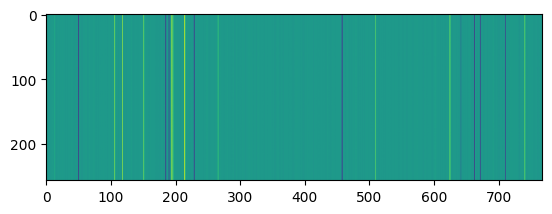

In [10]:
import matplotlib.pyplot as plt

plt.imshow(out[0].cpu().detach().numpy())

In [7]:
input_tensor = test_dataset[0]['data']
input_label = test_dataset[0]['label']

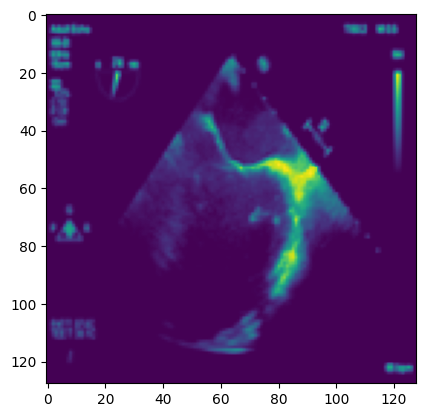

In [8]:
plt.imshow(input_tensor[0][0].cpu().detach().numpy())

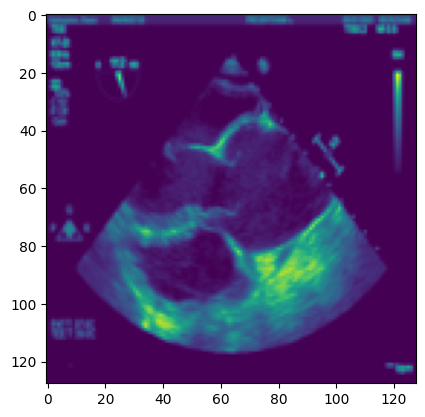

In [9]:
input_tensor = val_dataset[0]['data']
input_label = val_dataset[0]['label']
plt.imshow(input_tensor[0][0].cpu().detach().numpy())

tensor([[0.4505, 0.4051, 0.4873]], device='cuda:0', grad_fn=<AddmmBackward0>)
tensor([[0.5000, 0.0000, 0.1429]], dtype=torch.float64)


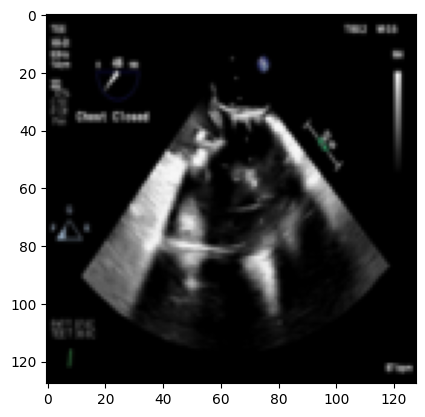

In [10]:
# get embeddings

# load datasets
index = np.random.randint(len(test_dataset))
input_tensor = test_dataset[index]['data']
input_label = test_dataset[index]['label']

plt.imshow(input_tensor[:,0].permute(1,2,0).cpu().detach().numpy())

out = get_embedding(model, 'norm', input_tensor.to(device).unsqueeze(0))

# plt.imshow(out[0].cpu().detach().numpy())

print(model(input_tensor.unsqueeze(0).to(device)))
print(input_label)

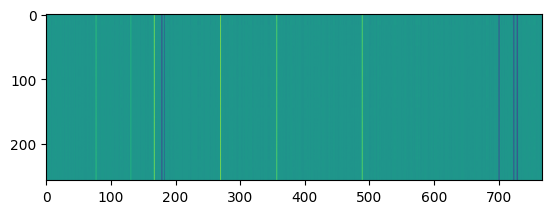

In [11]:
plt.imshow(out[0].cpu().detach().numpy())

In [12]:
len(train_dataset)

607123

In [13]:
len(train_dataset)

607123

In [15]:
dataset = train_dataset
trainsavepath = './train_embeddings'
valsavepath = './val_embeddings'
os.mkdir(trainsavepath)
os.mkdir(valsavepath)

current_acc = -1
current_prepost = -1
outputs = []
for index in tqdm.tqdm(range(len(dataset))):
    if current_acc != dataset[index]['acc'] or current_prepost != dataset[index]['prepost']: # if the study changes, then
        if current_acc == -1 or current_prepost == -1: # Check if this is the first iteration
            current_acc = dataset[index]['acc']
            current_prepost = dataset[index]['prepost']
            input_tensor = dataset[index]['data']
            input_label = dataset[index]['label']
            outputs.append(get_embedding(model, 'norm', input_tensor.to(device).unsqueeze(0))[0].cpu().detach().numpy())
            continue
        outputs = np.array(outputs)
        if index % 20 == 0:
            np.save(f'{valsavepath}/{current_acc}-{current_prepost}_x.npy', outputs)
            np.save(f'{valsavepath}/{current_acc}-{current_prepost}_y.npy', input_label.cpu().detach().numpy())
        else:
            np.save(f'{trainsavepath}/{current_acc}-{current_prepost}_x.npy', outputs)
            np.save(f'{trainsavepath}/{current_acc}-{current_prepost}_y.npy', input_label.cpu().detach().numpy())
        current_acc = dataset[index]['acc']
        current_prepost = dataset[index]['prepost']
        outputs = []
        break
    input_tensor = dataset[index]['data']
    input_label = dataset[index]['label']
    outputs.append(get_embedding(model, 'norm', input_tensor.to(device).unsqueeze(0))[0].cpu().detach().numpy())

  0%|          | 0/607123 [00:00<?, ?it/s]

  0%|          | 8/607123 [00:02<59:43:45,  2.82it/s]


In [ ]:
# dataset = val_dataset
# savepath = './val_embeddings'
# # os.mkdir(savepath)

# current_acc = -1
# current_prepost = -1
# outputs = []
# for index in tqdm.tqdm(range(len(dataset))):
#     if current_acc != dataset[index]['acc'] or current_prepost != dataset[index]['prepost']:
#         if current_acc == -1 or current_prepost == -1: 
#             current_acc = dataset[index]['acc']
#             current_prepost = dataset[index]['prepost']
#             input_tensor = dataset[index]['data']
#             input_label = dataset[index]['label']
#             outputs.append(get_embedding(model, 'norm', input_tensor.to(device).unsqueeze(0))[0].cpu().detach().numpy())
#             continue
#         outputs = np.array(outputs)
#         np.save(f'{savepath}/{current_acc}-{current_prepost}_x.npy', outputs)
#         np.save(f'{savepath}/{current_acc}-{current_prepost}_y.npy', input_label.cpu().detach().numpy())
#         current_acc = dataset[index]['acc']
#         current_prepost = dataset[index]['prepost']
#         outputs = []
    
#     input_tensor = dataset[index]['data']
#     input_label = dataset[index]['label']
#     outputs.append(get_embedding(model, 'norm', input_tensor.to(device).unsqueeze(0))[0].cpu().detach().numpy())

100%|██████████| 6099/6099 [35:12<00:00,  2.89it/s]


In [ ]:
dataset = test_dataset
savepath = './test_embeddings'
os.mkdir(savepath)

current_acc = -1
current_prepost = -1
outputs = []
for index in tqdm.tqdm(range(len(dataset))):
    if current_acc != dataset[index]['acc'] or current_prepost != dataset[index]['prepost']:
        if current_acc == -1 or current_prepost == -1: 
            current_acc = dataset[index]['acc']
            current_prepost = dataset[index]['prepost']
            input_tensor = dataset[index]['data']
            input_label = dataset[index]['label']
            outputs.append(get_embedding(model, 'norm', input_tensor.to(device).unsqueeze(0))[0].cpu().detach().numpy())
            continue
        outputs = np.array(outputs)
        np.save(f'{savepath}/{current_acc}-{current_prepost}_x.npy', outputs)
        np.save(f'{savepath}/{current_acc}-{current_prepost}_y.npy', input_label.cpu().detach().numpy())
        current_acc = dataset[index]['acc']
        current_prepost = dataset[index]['prepost']
        outputs = []
    input_tensor = dataset[index]['data']
    input_label = dataset[index]['label']
    outputs.append(get_embedding(model, 'norm', input_tensor.to(device).unsqueeze(0))[0].cpu().detach().numpy())

  0%|          | 17/46064 [00:05<4:07:39,  3.10it/s]